# Cavity haloscopes (beta)

In cavity haloscope experiments, a cavity in a static magnetic field converts an axion signal into resonant microwave power. In this tutorial we follow a cylindrical cavity through mode solving, tuning and receiver sensitivity. The modes are axisymmetric, with no azimuthal variation.

> **Beta.** The `axionfem.cavity`, `axionfem.cavity_xsec`, `axionfem.haloscope` and `axionfem.haloscope_presets` modules are beta in this release: they are checked against analytic cavity solutions and published haloscope parameters, but their interfaces may still change.

## Form factor

The dimensionless form factor measures electric-field overlap with the static field:

$$
C=\frac{\left|\int_V \mathbf E\cdot\mathbf B_0\,dV\right|^2}{B_{\rm ref}^2 V\int_V\varepsilon_r|\mathbf E|^2\,dV}.
$$

Here $\varepsilon_r$ is relative permittivity. The volume $V$ excludes conductors and includes dielectrics; $B_{\rm ref}$ is the cavity's rms static field here.

In [1]:
import json, math, tempfile, warnings
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.optimize import brentq
from scipy.special import j0, y0, jn_zeros

import axionfem as af
from axionfem import cavity as cv, haloscope as hs
from axionfem.haloscope_presets import PRESETS, REPRODUCIBLE

print("axionFEM", af.__version__)
RUNS = Path(tempfile.mkdtemp(prefix="axf_cavity_"))   # solver run directories
plt.rcParams.update({"figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# fixed categorical order
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
CHI0 = jn_zeros(0, 3)                      # zeros of J0: 2.405, 5.520, 8.654

axionFEM 0.1.0


## Empty copper cylinder

For uniform wall resistance and no dielectric loss, the intrinsic quality factor is

$$
Q_0 = \frac{G}{R_s}, \qquad
G = \frac{\omega\int_V \mu |\mathbf H|^2\,dV}
{\oint_{\partial V}|\mathbf H_t|^2\,dA}.
$$

Here $\omega$ is angular frequency, $\mu$ is permeability and $\mathbf H_t$ is the tangential wall field. The geometry factor $G$ and surface resistance $R_s$ are in ohms. Losses are evaluated on the lossless mode, assuming small losses.

In the classical skin regime (mean free path much smaller than skin depth), resistivity $\rho$ at the operating temperature gives

$$
R_s = \sqrt{\pi f\mu_0\rho}.
$$

Here $f$ is frequency and $\mu_0$ is vacuum permeability. The cold-copper example uses an anomalous-skin model. `surface_resistance` evaluates the chosen model at frequency $f$. These ideal surfaces omit joints, roughness and magnetic-field effects; predictions should use resistance measured at the operating field.

We define the copper model and cylinder dimensions and compare surface resistances for the loss calculation.

In [2]:
RHO300 = 1.725e-8                                # copper at 300 K [ohm m] (CRC)
CU_RF = {"model": "anomalous", "RRR": 100, "rho_300K_ohm_m": RHO300, "rho_l_ohm_m2": 6.6e-16,
         "specularity": 0.0, "T_K": 0.15}
CU = {"kind": "conductor", "rf": CU_RF}          # perfect at RF for the field solve; R_s enters perturbatively

F0 = 650e6
A = CHI0[0] * cv.C_LIGHT / (2 * math.pi * F0)    # radius for TM010 at 650 MHz
L = A / 0.21                                     # ADMX-like aspect ratio (21 cm x 1 m)
print(f"a = {A*100:.2f} cm, L = {L*100:.1f} cm, V = {math.pi*A*A*L*1e3:.1f} L")
print(f"R_s(650 MHz): anomalous RRR 100 {cv.surface_resistance(CU_RF, F0)*1e3:.3f} mOhm, "
      f"extreme-anomalous limit {cv.surface_resistance(dict(CU_RF, RRR=1e6), F0)*1e3:.3f} mOhm, "
      f"300 K skin {cv.skin_Rs(F0, RHO300)*1e3:.3f} mOhm")

a = 17.65 cm, L = 84.1 cm, V = 82.3 L
R_s(650 MHz): anomalous RRR 100 1.042 mOhm, extreme-anomalous limit 0.843 mOhm, 300 K skin 6.653 mOhm


### Geometry and mode solve

`pillbox_design` returns a `Design`; `solve` returns modes and diagnostics.

We build and solve the empty cylinder to obtain its modes and diagnostics.

In [3]:
d = cv.pillbox_design(A, L, h=0.03, modes=8, wall_material=CU, Bz=1.0)
print(json.dumps({k: d.doc[k] for k in ("background", "fullwave", "cavity")}, default=float))
res = d.solve(RUNS / "pillbox", verbose=0)
print(f"{res.data['mesh']['dofs']} DOFs")
cav = res.data["fullwave"]["cavity"]
print(f"cavity regions {cav['regions']}, V = {cav['volume_m3']*1e3:.2f} L, B_ref = {cav['B_ref']} = {cav['B_ref_T']} T")

{"background": {"type": "uniform", "Bz": 1.0}, "fullwave": {"modes": 8, "families": ["TE", "TM"], "boundary": "pec"}, "cavity": {"interior_point": [0.08826348295016158, 0.0]}}
7363 DOFs
cavity regions ['cavity'], V = 82.29 L, B_ref = volume rms of B0 over the cavity = 1.0 T


### Mode properties

`cavity_modes` lists frequency, form factor and losses. We tabulate the mode properties alongside analytic cylinder values to check the solve.

In [4]:
modes = res.cavity_modes()
ref = cv.pillbox_modes(A, L, 1.4e9)
print(f"{'mode':8s}{'f [MHz]':>11s}{'f/f_exact-1':>13s}{'C':>10s}{'C exact':>9s}{'G [ohm]':>9s}"
      f"{'G/G_exact-1':>13s}{'Q0':>10s}{'Q0 (300 K)':>12s}")
for m in modes[:10]:
    x = min((q for q in ref if q["family"] == m["family"]), key=lambda q: abs(q["f_Hz"] - m["f_Hz"]))
    name = f"{m['family']}0{x['n']}{x['p']}"
    Q300 = m["G_ohm"] / cv.skin_Rs(m["f_Hz"], RHO300)
    print(f"{name:8s}{m['f_Hz']/1e6:11.4f}{m['f_Hz']/x['f_Hz']-1:13.1e}{m['C']:10.2e}{x['C']:9.4f}"
          f"{m['G_ohm']:9.2f}{m['G_ohm']/x['G_ohm']-1:13.1e}{m['Q0']:10.3g}{Q300:12.3g}")
tm010 = modes[0]

mode        f [MHz]  f/f_exact-1         C  C exact  G [ohm]  G/G_exact-1        Q0  Q0 (300 K)
TM010      650.0002      3.8e-07  6.92e-01   0.6917   374.37     -1.4e-06  3.59e+05    5.63e+04
TM011      674.0167      7.0e-07  3.25e-14   0.0000   330.79     -1.9e-06  3.11e+05    4.88e+04
TM012      741.4130      1.7e-06  8.73e-15   0.0000   363.86     -5.2e-06  3.22e+05    5.12e+04
TM013      841.8349      3.7e-06  5.89e-15   0.0000   413.14     -1.2e-05  3.38e+05    5.46e+04
TM014      965.0287      7.9e-06  4.69e-16   0.0000   473.60     -2.4e-05  3.56e+05    5.84e+04
TE011     1050.9196      8.6e-06  0.00e+00   0.0000   744.77     -5.8e-05  5.32e+05     8.8e+04
TE012     1095.3685      1.1e-05  0.00e+00   0.0000   813.30     -7.7e-05  5.66e+05    9.42e+04
TM015     1103.3976      1.6e-05  5.85e-16   0.0000   541.49     -4.3e-05  3.75e+05    6.25e+04
TE013     1165.6919      1.5e-05  0.00e+00   0.0000   925.29     -1.2e-04  6.19e+05    1.04e+05
TM016     1251.9271      3.1e-05  2.58e-

The fundamental TM mode couples strongly to the axial field; sign changes suppress higher-mode overlap. Mesh convergence, including $G$, should be checked before using $Q_0$.

### Mode fields

The electric-field maps and radial samples expose cancellations in higher modes.

We plot the fields and compare radial samples with analytic profiles to examine these cancellations.

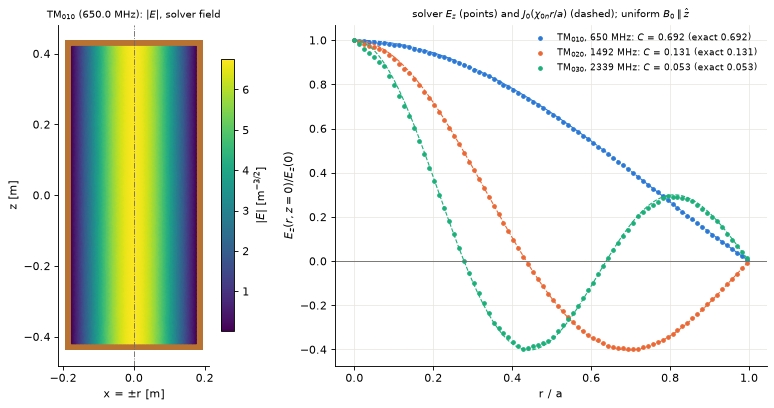

TM010: max |E_z/E_z(0) - J0(chi r/a)| = 6.7e-03
TM020: max |E_z/E_z(0) - J0(chi r/a)| = 1.4e-02
TM030: max |E_z/E_z(0) - J0(chi r/a)| = 3.1e-02


In [5]:
def draw_design(ax, design, colors=None, title="", mirror=False):
    # draw the rect / union-of-rect regions of an axisymmetric design in the (r, z) half-plane (both halves: mirror)
    colors = colors or {}
    def rects(shape):
        if "rect" in shape:
            yield shape["rect"]
        for s in shape.get("union", []):
            yield from rects(s)
    for reg in design.doc["regions"]:
        c = colors.get(reg["name"], "#b87333" if reg["name"] == "wall" else "#d6e6f5")
        for rc in rects(reg["shape"]):
            (r0, r1), (z0, z1) = rc["r"], rc["z"]
            for sgn in ((1, -1) if mirror else (1,)):
                lo, hi = sorted((sgn * r0, sgn * r1))
                ax.add_patch(plt.Rectangle((lo, z0), hi - lo, z1 - z0, fc=c, ec="none"))
    ax.axvline(0, color=GREY, lw=0.8, ls="-.")
    ax.set_aspect("equal"); ax.autoscale_view(); ax.grid(False)
    ax.set_xlabel("x = ±r [m]" if mirror else "r [m]"); ax.set_ylabel("z [m]"); ax.set_title(title, fontsize=9)

# TM020, TM030: targeted solves; the coupled mode is the one with the largest C among those returned
f0n0 = [cv.C_LIGHT * x / (2 * math.pi * A) for x in CHI0]
sols = [(res, tm010)]
for n in (1, 2):
    rn = cv.pillbox_design(A, L, h=0.015, modes=4, families=("TM",), wall_material=CU,
                           target_f_Hz=f0n0[n]).solve(RUNS / f"pillbox_tm0{n + 1}0", verbose=0)
    sols.append((rn, max(rn.cavity_modes(), key=lambda q: q["C"] or 0.0)))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw={"width_ratios": [1, 1.9]})
F = res.cavity_mode_field(tm010)                  # E, H on the cavity mesh (normalized to int |E|^2 dV = 1)
draw_design(ax0, d, mirror=True, title=f"TM$_{{010}}$ ({tm010['f_Hz']/1e6:.1f} MHz): $|E|$, solver field")
for sgn in (1, -1):
    tpc = ax0.tripcolor(mtri.Triangulation(sgn * F["r"], F["z"], F["tris"]), F["Emag"], shading="gouraud",
                        cmap="viridis", rasterized=True)
fig.colorbar(tpc, ax=ax0, shrink=0.8, label=r"$|E|$ [m$^{-3/2}$]")
r = np.linspace(0.0, 0.995 * A, 80)
for (rn, m), n, col in zip(sols, range(3), (BLUE, ORANGE, GREEN)):
    P = rn.cavity_mode_sample(m, r, np.zeros_like(r))
    ax1.plot(r / A, j0(CHI0[n] * r / A), color=col, lw=1.0, ls="--")
    ax1.plot(r / A, P["E_z"] / P["E_z"][0], "o", ms=3.2, color=col,
             label=f"TM$_{{0{n+1}0}}$, {m['f_Hz']/1e6:.0f} MHz: $C$ = {m['C']:.3f} (exact {4/CHI0[n]**2:.3f})")
ax1.axhline(0, color=GREY, lw=0.8)
ax1.set_xlabel("r / a"); ax1.set_ylabel(r"$E_z(r, z=0)/E_z(0)$")
ax1.set_title(r"solver $E_z$ (points) and $J_0(\chi_{0n}r/a)$ (dashed); uniform $B_0\parallel\hat z$", fontsize=9)
ax1.legend(fontsize=8.5, loc="upper right")
fig.tight_layout(); plt.show()
for (rn, m), n in zip(sols, range(3)):
    ez = rn.cavity_mode_sample(m, r, 0 * r)["E_z"]
    print(f"TM0{n + 1}0: max |E_z/E_z(0) - J0(chi r/a)| = {np.max(np.abs(ez / ez[0] - j0(CHI0[n] * r / A))):.1e}")

## Tuning with a centred rod

Increasing rod radius raises the coupled frequency. `target_f_Hz` selects nearby modes; we refine metal surfaces to resolve thin rods.

We sweep the rod radius to compare the coupled mode's properties with analytic coaxial values.

In [6]:
B_OUT = A                                    # same outer radius and length as the pillbox
ratios = np.array([0.05, 0.08, 0.12, 0.17, 0.23, 0.30, 0.38, 0.46])
sweep = []
for x in ratios:
    a_rod = x * B_OUT
    exact = cv.coax_tm_mode(a_rod, B_OUT)
    dc = cv.coax_design(a_rod, B_OUT, L, h=0.02, modes=4, target_f_Hz=exact["f_Hz"], wall_material=CU)
    dc.doc["mesh"]["surface_size"] = min(0.02, a_rod / 4)
    rc = dc.solve(RUNS / f"coax_{x:.2f}", verbose=0)
    rows = rc.cavity_modes()
    best = max(rows, key=lambda q: q["C"] or 0.0)      # the axion-coupled mode = largest C
    sweep.append({"x": x, "a": a_rod, "exact": exact, "best": best, "all": rows})
print(f"{len(ratios)} solves")
print(f"{'a/b':>5s}{'f [MHz]':>10s}{'rel err':>10s}{'C':>8s}{'C exact':>9s}{'V [L]':>8s}{'G [ohm]':>9s}{'Q0':>10s}")
for s in sweep:
    b_, e = s["best"], s["exact"]
    print(f"{s['x']:5.2f}{b_['f_Hz']/1e6:10.2f}{b_['f_Hz']/e['f_Hz']-1:10.1e}{b_['C']:8.4f}{float(e['C']):9.4f}"
          f"{b_['V_m3']*1e3:8.1f}{b_['G_ohm']:9.1f}{b_['Q0']:10.3g}")

8 solves
  a/b   f [MHz]   rel err       C  C exact   V [L]  G [ohm]        Q0
 0.05    828.39   1.3e-04  0.7635   0.7637    82.1    190.2  1.57e+05
 0.08    869.46   5.6e-05  0.7721   0.7722    81.8    212.0   1.7e+05
 0.12    921.94   2.5e-05  0.7801   0.7802    81.1    229.1  1.77e+05
 0.17    989.00   9.8e-06  0.7873   0.7873    79.9    242.3   1.8e+05
 0.23   1076.18   4.6e-06  0.7933   0.7933    77.9    252.8  1.78e+05
 0.30   1192.63   5.7e-06  0.7983   0.7983    74.9    261.3  1.72e+05
 0.38   1354.26   1.6e-05  0.8024   0.8023    70.4    268.4  1.64e+05
 0.46   1560.97   3.8e-05  0.8052   0.8051    64.9    273.8  1.53e+05


We plot frequency, form factor and $Q_0$ against rod radius to show the tuning tradeoffs.

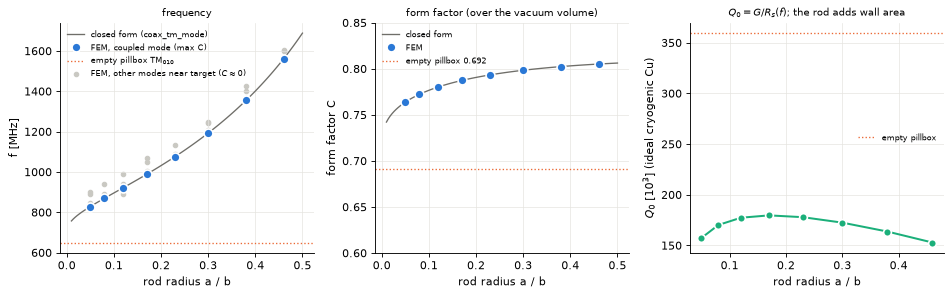

In [7]:
xs = np.linspace(0.01, 0.5, 120)
cf = [cv.coax_tm_mode(x * B_OUT, B_OUT) for x in xs]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
ax = axs[0]
for s in sweep:                                   # every mode the targeted solve returned (grey), coupled one coloured
    for q in s["all"]:
        ax.plot(s["x"], q["f_Hz"] / 1e6, "o", ms=4, color="#c9c8c2", zorder=1)
ax.plot(xs, [c["f_Hz"] / 1e6 for c in cf], color=GREY, lw=1.2, label="closed form (coax_tm_mode)")
ax.plot(ratios, [s["best"]["f_Hz"] / 1e6 for s in sweep], "o", ms=8, color=BLUE, mec="white", mew=1.5,
        label="FEM, coupled mode (max C)", zorder=3)
ax.axhline(F0 / 1e6, color=ORANGE, ls=":", lw=1.2, label="empty pillbox TM$_{010}$")
ax.plot([], [], "o", ms=4, color="#c9c8c2", label="FEM, other modes near target ($C\\approx0$)")
ax.set_xlabel("rod radius a / b"); ax.set_ylabel("f [MHz]"); ax.legend(fontsize=7.5); ax.set_title("frequency", fontsize=9)
ax = axs[1]
ax.plot(xs, [float(c["C"]) for c in cf], color=GREY, lw=1.2, label="closed form")
ax.plot(ratios, [s["best"]["C"] for s in sweep], "o", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM")
ax.axhline(4 / CHI0[0] ** 2, color=ORANGE, ls=":", lw=1.2, label="empty pillbox 0.692")
ax.set_xlabel("rod radius a / b"); ax.set_ylabel("form factor C"); ax.set_ylim(0.6, 0.85)
ax.legend(fontsize=7.5); ax.set_title("form factor (over the vacuum volume)", fontsize=9)
ax = axs[2]
ax.plot(ratios, [s["best"]["Q0"] / 1e3 for s in sweep], "o-", ms=7, color=GREEN, mec="white", mew=1.5)
ax.axhline(tm010["Q0"] / 1e3, color=ORANGE, ls=":", lw=1.2, label="empty pillbox")
ax.set_xlabel("rod radius a / b"); ax.set_ylabel(r"$Q_0$ [$10^3$] (ideal cryogenic Cu)")
ax.legend(fontsize=7.5); ax.set_title(r"$Q_0=G/R_s(f)$; the rod adds wall area", fontsize=9)
fig.tight_layout(); plt.show()

The rod changes usable volume and wall losses.

### Dielectric sleeve

The sleeve lowers frequency and adds dielectric loss, reducing $Q_0$. Its position controls the electric-energy fraction in sapphire.

We vary the sleeve position to compare mode properties and losses with analytic values.

In [8]:
EPS, TAND, W = 9.4, 1e-5, 0.01
def sleeve_design(r1):
    ds = cv.pillbox_design(A, L, h=0.03, modes=2, families=("TM",), wall_material=CU)
    ds.doc["materials"]["sapphire"] = {"kind": "linear", "eps_r": EPS, "tan_delta": TAND}
    ds.doc["regions"].insert(1, {"name": "sleeve", "shape": {"rect": {"r": [r1, r1 + W], "z": [-L / 2, L / 2]}},
                                 "material": "sapphire", "mesh_size": 0.0025})
    return ds

r1s = np.array([0.0, 0.03, 0.06, 0.09, 0.12, A - W])
sl = []
for r1 in r1s:
    m = sleeve_design(r1).solve(RUNS / f"sleeve_{r1:.3f}", verbose=0).cavity_modes()[0]
    sl.append((r1, m, cv.sleeve_tm_mode(A, r1, r1 + W, EPS)))
print(f"{'sleeve r [cm]':>14s}{'f [MHz]':>10s}{'rel err':>10s}{'C':>8s}{'C exact':>9s}{'Q_d':>10s}{'1/(tand fe)':>12s}{'Q_wall':>9s}{'Q0':>9s}")
for r1, m, e in sl:
    print(f"{r1*100:6.1f}-{(r1+W)*100:<7.1f}{m['f_Hz']/1e6:10.2f}{m['f_Hz']/e['f_Hz']-1:10.1e}{m['C']:8.4f}{e['C']:9.4f}"
          f"{m['Q_dielectric']:10.3g}{1/(TAND*e['fe_sleeve']):12.3g}{m['Q_wall']:9.3g}{m['Q0']:9.3g}")

 sleeve r [cm]   f [MHz]   rel err       C  C exact       Q_d 1/(tand fe)   Q_wall       Q0
   0.0-1.0        615.87   8.2e-04  0.5951   0.5936  7.77e+05    7.54e+05 3.88e+05 2.59e+05
   3.0-4.0        494.24   6.0e-05  0.3421   0.3420  1.95e+05    1.95e+05 4.57e+05 1.37e+05
   6.0-7.0        468.85   5.9e-06  0.3323   0.3323   1.8e+05     1.8e+05 4.02e+05 1.24e+05
   9.0-10.0       483.15   5.1e-07  0.3761   0.3761   1.9e+05     1.9e+05 3.28e+05  1.2e+05
  12.0-13.0       533.42   1.2e-07  0.4736   0.4736  2.41e+05    2.41e+05 2.54e+05 1.24e+05
  16.7-17.7       647.99   3.0e-07  0.6909   0.6909  1.36e+07    1.36e+07 3.17e+05  3.1e+05


We plot the sleeve geometry, frequency and form factor to compare the tuning results with analytic curves.

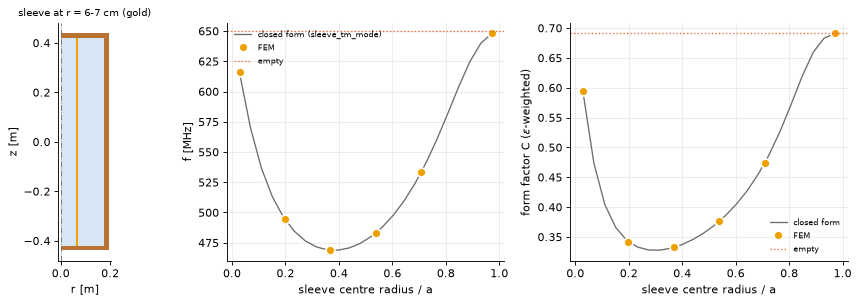

In [9]:
rc = np.linspace(0.0, A - W, 24)
ex = [cv.sleeve_tm_mode(A, r1, r1 + W, EPS) for r1 in rc]
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(11, 3.9), gridspec_kw={"width_ratios": [0.55, 1, 1]})
draw_design(ax0, sleeve_design(0.06), colors={"sleeve": GOLD}, title="sleeve at r = 6-7 cm (gold)")
mid = lambda r1: (r1 + W / 2) / A
ax1.plot(mid(rc), [e["f_Hz"] / 1e6 for e in ex], color=GREY, lw=1.2, label="closed form (sleeve_tm_mode)")
ax1.plot([mid(r1) for r1, _, _ in sl], [m["f_Hz"] / 1e6 for _, m, _ in sl], "o", ms=8, color=GOLD, mec="white",
         mew=1.5, label="FEM")
ax1.axhline(F0 / 1e6, color=ORANGE, ls=":", lw=1.2, label="empty")
ax1.set_xlabel("sleeve centre radius / a"); ax1.set_ylabel("f [MHz]"); ax1.legend(fontsize=7.5)
ax2.plot(mid(rc), [e["C"] for e in ex], color=GREY, lw=1.2, label="closed form")
ax2.plot([mid(r1) for r1, _, _ in sl], [m["C"] for _, m, _ in sl], "o", ms=8, color=GOLD, mec="white", mew=1.5,
         label="FEM")
ax2.axhline(4 / CHI0[0] ** 2, color=ORANGE, ls=":", lw=1.2, label="empty")
ax2.set_xlabel("sleeve centre radius / a"); ax2.set_ylabel(r"form factor C ($\varepsilon$-weighted)")
ax2.legend(fontsize=7.5)
fig.tight_layout(); plt.show()

## Sensitivity from modes

We combine solved mode properties in `haloscope.Cavity` with a receiver preset.

### Signal power

We use the same rms field normalization for the magnet strength and form factor. We calculate power and photon rate for the solved mode and the ADMX 1A preset to compare their signals.

In [10]:
f1, C1, V1, Q01 = tm010["f_Hz"], tm010["C"], tm010["V_m3"], tm010["Q0"]
m_eV = float(hs.freq_to_mass_eV(f1))
gD, gK = float(hs.g_axion(m_eV, "DFSZ")), float(hs.g_axion(m_eV, "KSVZ"))
admx_cav, admx_rx, admx_an = hs.preset_models("ADMX_1A")
B_ADMX = admx_cav.B_T
print(f"f = {f1/1e6:.3f} MHz, m_a = {m_eV*1e6:.3f} ueV, g_DFSZ = {gD:.3e}, g_KSVZ = {gK:.3e} GeV^-1")
for lab, kw in [("FEM pillbox, beta = 2", dict(V_m3=V1, C=C1, Q0=Q01, beta=2.0)),
                ("ADMX 1A preset (136 L, C 0.4, Q_L 5e4, beta 1)", dict(V_m3=admx_cav.V_m3, C=admx_cav.C,
                                                                       Q0=admx_cav.Q0, beta=admx_cav.beta))]:
    P = hs.signal_power(gD, f1, B_ADMX, kw["V_m3"], kw["C"], Q0=kw["Q0"], beta=kw["beta"])
    print(f"  {lab:48s}: P_DFSZ = {P:.3e} W = {P/(hs.H_PLANCK*f1):.1f} photons/s")
print(f"  radiometer: SNR 5 at T_sys = 0.5 K in 100 s over b = f/Q_a = {f1/hs.Q_a_shm():.0f} Hz needs "
      f"P = {5*hs.KB*0.5*math.sqrt(f1/hs.Q_a_shm()/100):.2e} W")

f = 650.000 MHz, m_a = 2.688 ueV, g_DFSZ = 3.733e-16, g_KSVZ = 1.006e-15 GeV^-1
  FEM pillbox, beta = 2                           : P_DFSZ = 4.555e-23 W = 105.8 photons/s
  ADMX 1A preset (136 L, C 0.4, Q_L 5e4, beta 1)  : P_DFSZ = 1.363e-23 W = 31.6 photons/s
  radiometer: SNR 5 at T_sys = 0.5 K in 100 s over b = f/Q_a = 959 Hz needs P = 1.07e-22 W


### Antenna coupling

Port coupling $\beta$ broadens the resonance from intrinsic $Q_0$ to loaded $Q_L$. With noise-equivalent axion bandwidth $\Delta f_{\rm eff}$,

$$
Q_L=\frac{Q_0}{1+\beta},\qquad \Delta f_{\rm eff}=\frac{f}{Q_a}.
$$

Here $Q_a$ describes the noise-equivalent axion width, rather than its full width at half maximum. For optimal weighting, unit analysis efficiency, dense tuning steps and no dead time, the scan rate at target signal-to-noise ratio (SNR) is

$$
\frac{df}{dt}=\frac{1}{{\rm SNR}^2\,\Delta f_{\rm eff}}\int d\delta\left[\frac{P(\delta)}{hf\,N_{\rm sys}(\delta)}\right]^2.
$$

Here $h$ is Planck's constant and $P(\delta)$ is received monochromatic signal power at detuning $\delta$; $hfN_{\rm sys}$ is noise power per bandwidth. `scan_rate` returns Hz/s of live integration at the target coupling and SNR. The curves use optimal weighting and the binned estimator of Kim et al., arXiv:2001.05605, with their respective bandwidth conventions and normalizations.

We vary antenna coupling to compare scan rates and locate their optima.

beta_opt: optimal weighting 2.000;  Kim 2020 (Q_a,kim = 1e6) 2.223
scan rate at DFSZ, SNR 5, beta = 2: 7.74 Hz/s = 0.67 MHz/day (KSVZ: 35.3 MHz/day)


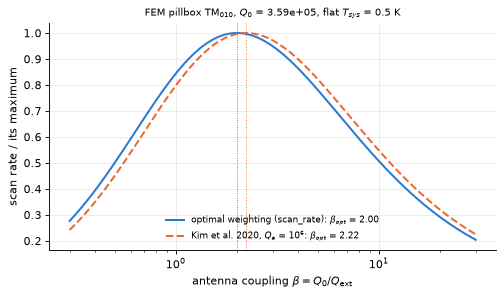

In [11]:
cav1 = hs.Cavity(B_T=B_ADMX, V_m3=V1, C=C1, Q0=Q01, beta=2.0, label="FEM pillbox")
betas = np.geomspace(0.3, 30, 150)
r_opt = np.array([hs.scan_rate(f1, hs.Cavity(B_ADMX, V1, C1, Q01, b), admx_rx, g_GeV=gD) for b in betas])
r_kim = np.array([hs.scan_rate_kim2020(f1, hs.Cavity(B_ADMX, V1, C1, Q01, b), g_GeV=gD, T_sys_K=0.5, Q_a_kim=1e6)
                  for b in betas])
b_opt = hs.beta_opt(f1, cav1, admx_rx, g_GeV=gD)
b_kim = hs.beta_opt_kim2020(Q01, 1e6)
rate1 = hs.scan_rate(f1, cav1, admx_rx, g_GeV=gD, snr=5.0)
print(f"beta_opt: optimal weighting {b_opt:.3f};  Kim 2020 (Q_a,kim = 1e6) {b_kim:.3f}")
print(f"scan rate at DFSZ, SNR 5, beta = 2: {rate1:.3g} Hz/s = {rate1*86400/1e6:.2f} MHz/day "
      f"(KSVZ: {hs.scan_rate(f1, cav1, admx_rx, g_GeV=gK, snr=5.0)*86400/1e6:.1f} MHz/day)")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(betas, r_opt / r_opt.max(), color=BLUE, label=f"optimal weighting (scan_rate): $\\beta_{{opt}}$ = {b_opt:.2f}")
ax.plot(betas, r_kim / r_kim.max(), color=ORANGE, ls="--",
        label=f"Kim et al. 2020, $Q_{{a}}$ = $10^6$: $\\beta_{{opt}}$ = {b_kim:.2f}")
for b, c in ((b_opt, BLUE), (b_kim, ORANGE)):
    ax.axvline(b, color=c, lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlabel(r"antenna coupling $\beta=Q_0/Q_{\rm ext}$")
ax.set_ylabel("scan rate / its maximum")
ax.set_title(f"FEM pillbox TM$_{{010}}$, $Q_0$ = {Q01:.2e}, flat $T_{{sys}}$ = 0.5 K", fontsize=9)
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

### Tuning branch

We calculate coupling reach and live time across the rod sweep by interpolating solved mode properties.

In [12]:
fb = np.array([s["best"]["f_Hz"] for s in sweep])
interp = lambda key: (lambda f, v=np.array([s["best"][key] for s in sweep]): float(np.interp(f, fb, v)))
branch = hs.Cavity(B_T=B_ADMX, V_m3=interp("V_m3"), C=interp("C"), Q0=interp("Q0"), beta=2.0, label="rod branch")
snrA = hs.snr_required(admx_an.get("threshold_sigma"), admx_an.get("confidence", 0.90), admx_an.get("snr_target"))
rateA = admx_an["rate_Hz_s"]
f_br = np.linspace(fb[0], fb[-1], 40)
g_br = hs.g_limit_scan(f_br, branch, admx_rx, rate_Hz_s=rateA, snr=snrA)
g_pb = hs.g_limit_scan(f1, cav1, admx_rx, rate_Hz_s=rateA, snr=snrA)
recA = hs.preset_limit("ADMX_1A")
print(f"SNR target {snrA:.3f} (ADMX 1A: 90% zero-excess), rate {rateA:.3f} Hz/s")
print(f"empty pillbox @ {f1/1e6:.0f} MHz : g_lim = {g_pb:.3e} GeV^-1 = {g_pb/gK:.2f} x KSVZ")
print(f"ADMX 1A preset @ 660 MHz  : computed {recA['g_GeV']:.3e} GeV^-1")
print(f"rod branch {fb[0]/1e6:.0f}-{fb[-1]/1e6:.0f} MHz: g_lim / g_KSVZ from {g_br[0]/hs.g_axion(hs.freq_to_mass_eV(f_br[0]),'KSVZ'):.2f}"
      f" to {g_br[-1]/hs.g_axion(hs.freq_to_mass_eV(f_br[-1]),'KSVZ'):.2f}")
cover = hs.time_to_cover(fb[0], fb[-1], branch, admx_rx, g="DFSZ", snr=snrA)
print(f"live time to cover the rod branch at DFSZ (SNR {snrA:.2f}): {cover['t_yr']:.2f} yr")

SNR target 1.282 (ADMX 1A: 90% zero-excess), rate 4.433 Hz/s
empty pillbox @ 650 MHz : g_lim = 1.644e-16 GeV^-1 = 0.16 x KSVZ
ADMX 1A preset @ 660 MHz  : computed 2.435e-16 GeV^-1
rod branch 828-1561 MHz: g_lim / g_KSVZ from 0.17 to 0.14
live time to cover the rod branch at DFSZ (SNR 1.28): 0.12 yr


### A smaller cavity

We calculate coupling reach for a smaller cylinder with receiver noise that varies with detuning.

In [13]:
BH, LH = 0.0508, 0.254
hay_cav, hay_rx, hay_an = hs.preset_models("HAYSTAC_2017")
snrH = hs.snr_required(hay_an.get("threshold_sigma"), hay_an.get("confidence", 0.90), hay_an.get("snr_target"))
hay = []
for ft in (5.6e9, 5.75e9, 5.9e9):
    a_r = brentq(lambda x: cv.coax_tm_mode(x, BH)["f_Hz"] - ft, 0.005, 0.045)
    dh = cv.coax_design(a_r, BH, LH, h=0.003, modes=3, target_f_Hz=ft, wall_material=CU)
    m = max(dh.solve(RUNS / f"haystac_{ft/1e9:.2f}", verbose=0).cavity_modes(), key=lambda q: q["C"] or 0)
    c = hs.Cavity(B_T=hay_cav.B_T, V_m3=m["V_m3"], C=m["C"], Q0=m["Q0"], beta=2.0)
    c = hs.Cavity(B_T=hay_cav.B_T, V_m3=m["V_m3"], C=m["C"], Q0=m["Q0"], beta=hs.beta_opt(m["f_Hz"], c, hay_rx))
    g = hs.g_limit_scan(m["f_Hz"], c, hay_rx, rate_Hz_s=hay_an["rate_Hz_s"], snr=snrH)
    hay.append((m["f_Hz"], g, m, c.beta))
    print(f"rod a = {a_r*100:.2f} cm: f = {m['f_Hz']/1e9:.4f} GHz, C = {m['C']:.3f}, V = {m['V_m3']*1e3:.3f} L, "
          f"Q0 = {m['Q0']:.3g}, beta_opt = {c.beta:.2f}, g_lim = {g:.3e} = "
          f"{g/hs.g_axion(hs.freq_to_mass_eV(m['f_Hz']), 'KSVZ'):.2f} x KSVZ")
recH = hs.preset_limit("HAYSTAC_2017")
print(f"HAYSTAC 2017 preset (C 0.5, Q0 3e4, V 1.545 L): computed {recH['x_KSVZ']:.2f} x KSVZ")

rod a = 2.42 cm: f = 5.6000 GHz, C = 0.806, V = 1.591 L, Q0 = 6.88e+04, beta_opt = 2.86, g_lim = 1.428e-14 = 1.65 x KSVZ
rod a = 2.49 cm: f = 5.7500 GHz, C = 0.806, V = 1.565 L, Q0 = 6.78e+04, beta_opt = 2.84, g_lim = 1.476e-14 = 1.66 x KSVZ
rod a = 2.55 cm: f = 5.9000 GHz, C = 0.806, V = 1.539 L, Q0 = 6.69e+04, beta_opt = 2.82, g_lim = 1.525e-14 = 1.67 x KSVZ
HAYSTAC 2017 preset (C 0.5, Q0 3e4, V 1.545 L): computed 2.62 x KSVZ


### Model sensitivities

Lower curves reach weaker axion couplings under the chosen receiver and scan assumptions.

We plot the cavity and preset sensitivities against axion mass to compare their coupling reach.

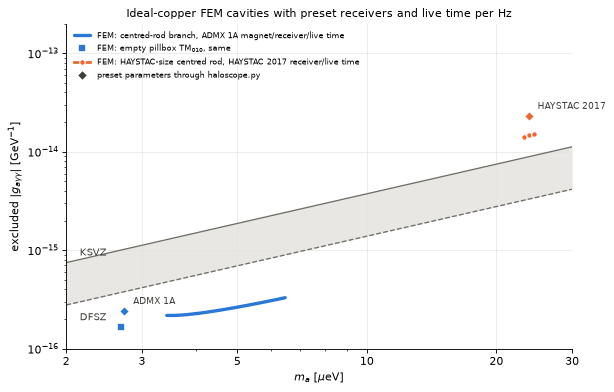

In [14]:
mm = np.geomspace(2, 30, 300)
gKl, gDl = hs.g_axion(mm * 1e-6, "KSVZ"), hs.g_axion(mm * 1e-6, "DFSZ")
fig, ax = plt.subplots(figsize=(7.8, 5.0))
ax.fill_between(mm, gDl, gKl, color="#d9d8d2", alpha=0.6, lw=0)
ax.plot(mm, gKl, color=GREY, lw=1.2); ax.plot(mm, gDl, color=GREY, lw=1.2, ls="--")
ax.text(2.15, gKl[0] * 1.18, "KSVZ", color="#3d3d3a", fontsize=9)
ax.text(2.15, gDl[0] * 0.70, "DFSZ", color="#3d3d3a", fontsize=9)
# ADMX-like: rod branch and empty pillbox
ax.plot(hs.freq_to_mass_eV(f_br) * 1e6, g_br, color=BLUE, lw=3, solid_capstyle="round",
        label="FEM: centred-rod branch, ADMX 1A magnet/receiver/live time")
ax.plot(m_eV * 1e6, g_pb, "s", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM: empty pillbox TM$_{010}$, same")
# HAYSTAC-like
fh = np.array([h[0] for h in hay]); gh = np.array([h[1] for h in hay])
ax.plot(hs.freq_to_mass_eV(fh) * 1e6, gh, "-o", color=ORANGE, lw=2.5, ms=5, mec="white",
        label="FEM: HAYSTAC-size centred rod, HAYSTAC 2017 receiver/live time")
# preset model sensitivities
for name, col in (("ADMX_1A", BLUE), ("HAYSTAC_2017", ORANGE)):
    rr = hs.preset_limit(name); mp = hs.freq_to_mass_eV(rr["f_Hz"]) * 1e6
    ax.plot(mp, rr["g_GeV"], "D", ms=6, color=col, mec="white", mew=1.2, zorder=4)
    ax.annotate(name.replace("_", " "), (mp, rr["g_GeV"]), textcoords="offset points",
                xytext=(8, 6), fontsize=8, color="#3d3d3a")
ax.plot([], [], "D", ms=6, color="#3d3d3a", mec="white", label="preset parameters through haloscope.py")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(2, 30); ax.set_ylim(1e-16, 2e-13)
ax.set_xticks([2, 3, 5, 10, 20, 30]); ax.set_xticklabels(["2", "3", "5", "10", "20", "30"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel(r"$m_a$ [$\mu$eV]"); ax.set_ylabel(r"excluded $|g_{a\gamma\gamma}|$ [GeV$^{-1}$]")
ax.set_title("Ideal-copper FEM cavities with preset receivers and live time per Hz", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left"); fig.tight_layout(); plt.show()

## Published receiver presets

The sensitivity layer needs only cavity and receiver parameters, so it also evaluates the published haloscope runs from their reported hardware. For received power $P$, system temperature $T_{\rm sys}$, integration time $t$ and noise bandwidth $b$, the radiometer relation is

$$
\mathrm{SNR}=\frac{P}{k_B T_{\rm sys}}\sqrt{\frac{t}{b}}.
$$

The scan-rate integral above follows from combining densely spaced tunings with optimal weighting. The cell prints power in watts, scan rate in hertz per second and the coupling that maximizes that rate for a reference cavity.

We evaluate a reference cavity with a receiver of flat 1 K system noise.

In [15]:
P = hs.signal_power(1e-15, 1e9, 8.0, 0.1, 0.5, Q_L=5e4, beta=1.0)
cav_ref = hs.Cavity(B_T=8.0, V_m3=0.1, C=0.5, Q0=1.5e5, beta=2.0)
rx_ref = hs.Receiver(T_sys_K=1.0)
r_ref = hs.scan_rate(1e9, cav_ref, rx_ref, g_GeV=1e-15, snr=5.0, Q_a=1e6)
print(f"P(beta=1)       = {P:.6e} W")
print(f"df/dt (beta=2)  = {r_ref:.6f} Hz/s")
print(f"beta_opt (flat) = {hs.beta_opt(1e9, cav_ref, rx_ref, g_GeV=1e-15):.6f}")
print(f"Q_a (SHM 220/232 km/s) = {hs.Q_a_shm():.6e}")

P(beta=1)       = 8.086129e-23 W
df/dt (beta=2)  = 38.315285 Hz/s
beta_opt (flat) = 2.000000
Q_a (SHM 220/232 km/s) = 6.779483e+05


`preset_limit` combines a preset's cavity, receiver and analysis settings. The table and plot show the computed coupling reach in inverse GeV; lower values mean sensitivity to weaker signals. Presets use different thresholds and scan or dwell strategies, so compare their analysis settings as well as their hardware. KSVZ and DFSZ curves mark two QCD axion models.

In [16]:
rows = []
for n in REPRODUCIBLE:
    r = hs.preset_limit(n)
    rows.append((n, r['f_Hz'] / 1e9, r['snr'], PRESETS[n]['analysis']['limit_type'], r['g_GeV']))
print(f"{'preset':14s} {'f[GHz]':>8s} {'SNR':>5s} {'limit':>17s} {'g [GeV^-1]':>10s}")
for n, f, s, lt, g in rows:
    print(f'{n:14s} {f:8.4f} {s:5.2f} {lt:>17s} {g:10.3e}')
print('ADMX 1D (no live time published): implied', hs.implied_rate('ADMX_1D'))

preset           f[GHz]   SNR             limit g [GeV^-1]
ADMX_1A          0.6600  1.28 likelihood_approx  2.435e-16
HAYSTAC_2017     5.7500  5.10         threshold  2.330e-14
HAYSTAC_2021     4.1400  5.10         threshold  1.328e-14
HAYSTAC_2023     4.4900  5.10         threshold  1.444e-14
CAPP_12TB        1.1000  5.00         threshold  6.123e-16
TASEH_2022       4.7500  5.00         threshold  8.848e-14
QUAX_2019        9.0670  1.64        likelihood  9.588e-13
QUAX_2021       10.4018  1.28        likelihood  7.714e-14
ORGAN_Q_2025     6.2500  8.33         threshold  2.332e-13
ADMX 1D (no live time published): implied {'rate_Hz_s': 305.3564926771096, 'live_time_s': 687720.762571302, 'live_time_days': 7.959731048278958}


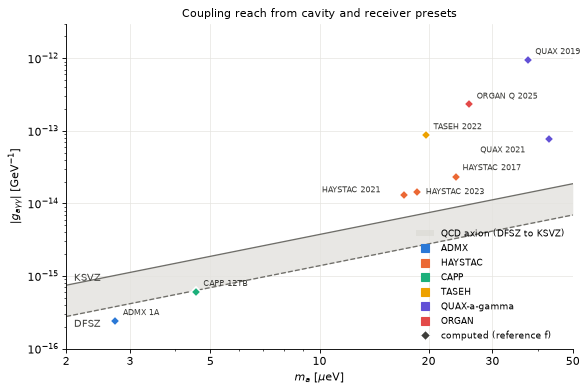

In [17]:
EXP_COL = {'ADMX': '#2a78d6', 'HAYSTAC': '#eb6834', 'CAPP': '#1baf7a', 'TASEH': '#eda100',
           'QUAX-a-gamma': '#6250d6', 'ORGAN': '#e34948'}      # one hue per experiment
m = np.geomspace(2, 50, 200)
gK = hs.g_axion(m * 1e-6, 'KSVZ'); gD = hs.g_axion(m * 1e-6, 'DFSZ')
fig, ax = plt.subplots(figsize=(7.5, 5.0))
ax.fill_between(m, gD, gK, color='#d9d8d2', alpha=0.6, lw=0, label='QCD axion (DFSZ to KSVZ)')
ax.plot(m, gK, color='#6f6e69', lw=1.2); ax.plot(m, gD, color='#6f6e69', lw=1.2, ls='--')
ax.text(2.1, gK[0] * 1.15, 'KSVZ', color='#3d3d3a', fontsize=9)
ax.text(2.1, gD[0] * 0.72, 'DFSZ', color='#3d3d3a', fontsize=9)
OFF = {'HAYSTAC_2017': (6, 6), 'HAYSTAC_2023': (8, -2), 'HAYSTAC_2021': (-74, 2), 'QUAX_2021': (-62, -12)}
seen = set()
for name in REPRODUCIBLE:
    p = PRESETS[name]; c = EXP_COL[p['experiment']]
    fp = p['published']['f_Hz']; mp = hs.freq_to_mass_eV(fp) * 1e6
    lab = p['experiment'] if p['experiment'] not in seen else None
    seen.add(p['experiment'])
    if lab:                                     # scanned bands (0.04-200 MHz) are invisible at this scale
        ax.plot([], [], 's', ms=7, color=c, label=lab)
    ax.plot(mp, hs.preset_limit(name)['g_GeV'], 'D', ms=6, color=c, mec='white', mew=1.5, zorder=4)
    ax.annotate(name.replace('_', ' '), (mp, hs.preset_limit(name)['g_GeV']), textcoords='offset points',
                xytext=OFF.get(name, (7, 5)), fontsize=7.5, color='#3d3d3a')
ax.plot([], [], 'D', ms=6, color='#3d3d3a', mec='white', label='computed (reference f)')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(2, 50); ax.set_ylim(1e-16, 3e-12)
ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g'))
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_xticks([2, 3, 5, 10, 20, 30, 50])
ax.set_xlabel(r'$m_a$ [$\mu$eV]'); ax.set_ylabel(r'$|g_{a\gamma\gamma}|$ [GeV$^{-1}$]')
ax.set_title('Coupling reach from cavity and receiver presets', fontsize=10)
ax.legend(fontsize=8, loc='lower right', frameon=False)
fig.tight_layout()
plt.show()

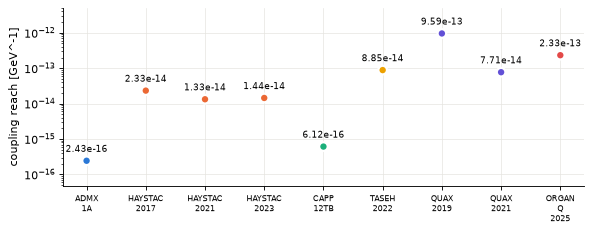

In [18]:
# coupling reach at each preset reference frequency
fig, ax = plt.subplots(figsize=(7.5, 3.0))
names = [r[0] for r in rows]; q = [r[-1] for r in rows]
ax.scatter(range(len(q)), q, s=60, c=[EXP_COL[PRESETS[n]['experiment']] for n in names], zorder=3,
           edgecolors='white', linewidths=2)
for i, v in enumerate(q):
    ax.annotate(f'{v:.2e}', (i, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
ax.set_xticks(range(len(q))); ax.set_xticklabels([n.replace('_', '\n') for n in names], fontsize=7.5)
ax.set_ylabel('coupling reach [GeV^-1]'); ax.set_yscale('log')
ax.margins(y=0.2)
fig.tight_layout(); plt.show()

### Optimize coupling with squeezing

Antenna coupling trades signal extraction against resonance width. The curves compare flat quantum-limited noise with a warmer cavity and squeezed input noise. Each rate is normalized to the corresponding unsqueezed baseline at its own optimum; dots mark the optimized coupling. The HAYSTAC 2023 receiver is the `HAYSTAC_2023` preset, built from the Table II averages of arXiv:2301.09721. The quantum-limited curve has a colder cavity than the preset receiver.

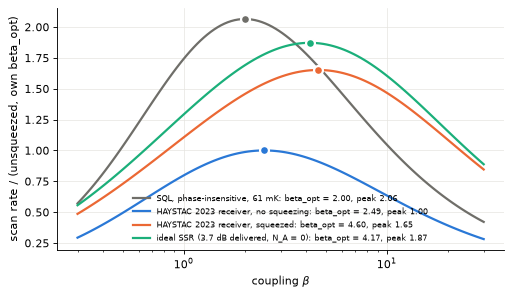

In [19]:
f = 4.49e9
cav, rxs, _ = hs.preset_models('HAYSTAC_2023'); rxs = replace(rxs, eta_snr=1.0)
un = replace(rxs, squeeze_dB=0.0)
ideal = hs.squeezed(0.061, hs.squeezer_gain_dB(10 ** -0.37, 0.60), squeeze_eff=0.60 / 0.775, eta_out=0.775)
cases = {'SQL, phase-insensitive, 61 mK': (hs.sql(0.061, eta_out=0.775), un),
         'HAYSTAC 2023 receiver, no squeezing': (un, un),
         'HAYSTAC 2023 receiver, squeezed': (rxs, un),
         'ideal SSR (3.7 dB delivered, N_A = 0)': (ideal, replace(ideal, squeeze_dB=0.0))}
betas = np.geomspace(0.3, 30, 120)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (lab, (rx, base)), c in zip(cases.items(), ['#6f6e69', '#2a78d6', '#eb6834', '#1baf7a']):
    ref = hs.scan_rate(f, replace(cav, beta=hs.beta_opt(f, cav, base)), base)
    r = np.array([hs.scan_rate(f, replace(cav, beta=b), rx) for b in betas]) / ref
    bo = hs.beta_opt(f, cav, rx); Eo = hs.scan_rate(f, replace(cav, beta=bo), rx) / ref
    ax.plot(betas, r, color=c, lw=2, label=f'{lab}: beta_opt = {bo:.2f}, peak {Eo:.2f}')
    ax.plot(bo, Eo, 'o', ms=8, color=c, mec='white', mew=2)
ax.set_xscale('log'); ax.set_xlabel(r'coupling $\beta$')
ax.set_ylabel('scan rate / (unsqueezed, own beta_opt)')
ax.legend(fontsize=7.5, frameon=False); fig.tight_layout()
plt.show()

### Time to cover a band

Supply frequency-dependent form factor and unloaded quality factor as callables. `time_to_cover` returns the live integration time needed to reach DFSZ across the band. The model assumes dense tuning and excludes tuning and calibration overhead.

In [20]:
C_of_f = lambda f: 0.45 - 0.1 * (f - 1.0e9) / 0.4e9        # stand-in for an FEM C(f) table
Q0_of_f = lambda f: 1.0e5 * (1.0e9 / f) ** (2 / 3)            # anomalous-skin scaling
cav = hs.Cavity(B_T=7.6, V_m3=0.136, C=C_of_f, Q0=Q0_of_f, beta=2.0)
for lab, rx in [('SQL @150 mK', hs.sql(0.15)), ('T_sys = 0.5 K', hs.Receiver(T_sys_K=0.5))]:
    out = hs.time_to_cover(1.0e9, 1.4e9, cav, rx, g='DFSZ', snr=5.0)
    print(f'{lab:14s}: {out["t_yr"]:.2f} yr live time for 1.0-1.4 GHz at DFSZ, SNR 5')

SQL @150 mK   : 0.18 yr live time for 1.0-1.4 GHz at DFSZ, SNR 5
T_sys = 0.5 K : 1.38 yr live time for 1.0-1.4 GHz at DFSZ, SNR 5


## Wall models and the quality factor

RF currents dissipate energy in a cavity's walls. The unloaded quality factor separates the mode's geometry from the wall material's surface resistance. For weak wall losses in a vacuum cavity with uniform resistance and negligible dielectric loss,

$$
Q_0=\frac{G}{R_s},\qquad
G=\frac{\omega\mu_0\int_V|\mathbf H|^2\,dV}{\oint|\mathbf H_t|^2\,dA}.
$$

$\mathbf H_t$ is the tangential magnetic field of the lossless mode. $G$ and $R_s$ are in ohms; $G$ stays fixed when all cavity dimensions scale together. This section evaluates the wall models, solves a pillbox mode and follows the loss into scan sensitivity.

We define the wall models used below (the `rf` blocks of the [design format](../docs/design_format.md)).

In [21]:
RED = "#e34948"
MU0, Z0 = cv.MU0, cv.Z0
CHI01 = 2.404825557695773

# --- the wall models used below (rf blocks of the design format, docs/design_format.md "Materials") ---------------
RHO300 = 1.725e-8          # copper at 300 K [ohm m] (CRC; docs/physics/surface_resistance.md Sec. 1)
RHOL_CU = 6.6e-16          # copper rho*l [ohm m^2] (docs/physics/surface_resistance.md Sec. 2.2)


def cu_cold(RRR, rho300=RHO300, T_K=4.0, p=0.0):
    "cryogenic copper: Reuter-Sondheimer anomalous skin effect, residual resistivity rho300/RRR, specularity p"
    return {"model": "anomalous", "RRR": RRR, "rho_300K_ohm_m": rho300, "rho_l_ohm_m2": RHOL_CU,
            "specularity": p, "T_K": T_K}


CU_300K = {"model": "skin", "rho_ohm_m": RHO300, "T_K": 300}
# niobium, low-T BCS fit (Dhakal et al. arXiv:1202.0811 Eq. 4; Sec. 3) + residual resistance R_res
NB = {"model": "bcs", "A_ohm_K": 2e-4, "f_ref": 1.5e9, "Delta_over_kTc": 17.67 / 9.25, "Tc_K": 9.25,
      "R_res_ohm": 0.0, "T_K": 2.0}
# vortex (flux-flow) parameters of Sec. 4 of docs/physics/surface_resistance.md: Nb3Sn-like and NbTi-like walls, free flux flow (f0 = 0)
NB3SN_FF = {"Bc2_T": 25.0, "rho_n_ohm_m": 1.5e-7, "lambda_m": 110e-9, "f_depin_Hz": 0.0}
NBTI_FF = {"Bc2_T": 11.0, "rho_n_ohm_m": 6e-7, "lambda_m": 300e-9, "f_depin_Hz": 0.0}


def flux_flow_only(ff, B_T=None, s=None, T_K=4.2):
    "a wall whose R_s is the vortex term alone (zero-field part set to a negligible 1e-30 ohm, as in the unit tests)"
    f = dict(ff)
    if B_T is not None:
        f["B_T"] = B_T
    if s is not None:
        f["orientation"] = s
    return {"model": "power", "Rs_ohm": 1e-30, "T_K": T_K, "flux_flow": f}


Rs = cv.surface_resistance                 # R_s(rf, f) [ohm]; scalar or array f

### Surface-resistance models

`surface_resistance(rf, f)` returns resistance in ohms for a material's `rf` settings and frequency in hertz.

### Normal skin effect

Use `skin` when the electron mean free path is short compared with skin depth, as in warm copper.

In [22]:
for f in (1e9, 5e9):
    d = math.sqrt(2 * RHO300 / (MU0 * 2 * math.pi * f))
    print(f"f = {f/1e9:.0f} GHz, copper 300 K: delta = {d*1e6:.3f} um, R_s = {Rs(CU_300K, f)*1e3:.3f} mOhm "
          f"(closed form {cv.skin_Rs(f, RHO300)*1e3:.3f}); 293 K value: {cv.skin_Rs(f, 1.678e-8)*1e3:.3f} mOhm")

f = 1 GHz, copper 300 K: delta = 2.090 um, R_s = 8.252 mOhm (closed form 8.252); 293 K value: 8.139 mOhm
f = 5 GHz, copper 300 K: delta = 0.935 um, R_s = 18.453 mOhm (closed form 18.453); 293 K value: 18.200 mOhm


### Anomalous skin effect

In cold copper, electrons travel farther between collisions. `anomalous` accounts for this nonlocal response; increasing purity eventually stops reducing the RF loss.

In [23]:
# extreme-anomalous limit at 1 GHz: closed form vs the model with a vanishing rho (alpha -> infinity)
w = 2 * math.pi * 1e9
R_inf = (math.sqrt(3) * RHOL_CU * (MU0 * w) ** 2 / (16 * math.pi)) ** (1 / 3)
R_lim = Rs({"model": "anomalous", "rho_ohm_m": 1e-16, "rho_l_ohm_m2": RHOL_CU, "T_K": 0.01}, 1e9)
print(f"R_inf(1 GHz): closed form {R_inf*1e3:.4f} mOhm, model at alpha -> inf {R_lim*1e3:.4f} mOhm (docs: 1.1234)")
print(f"specular / diffuse in that limit: "
      f"{Rs({'model': 'anomalous', 'rho_ohm_m': 1e-16, 'rho_l_ohm_m2': RHOL_CU, 'specularity': 1.0, 'T_K': 0.01}, 1e9) / R_lim:.4f}"
      f" (8/9 = {8/9:.4f})")

# classical / anomalous ratio for the builtin copper (rho = 1.7e-10, RRR ~ 100): Sec. 1.1 of docs/physics/surface_resistance.md
CU_BUILTIN = {"model": "anomalous", "rho_ohm_m": 1.7e-10, "rho_l_ohm_m2": RHOL_CU, "T_K": 0.03}
DOC = {0.12e6: 0.996, 1e6: 0.976, 5e6: 0.934, 10e6: 0.906, 30e6: 0.848, 100e6: 0.770, 200e6: 0.721, 1e9: 0.604, 5e9: 0.492}
print(f"\n{'f':>9s}{'alpha':>9s}{'R_skin/R_RS':>13s}{'docs':>7s}")
for f, ref in DOC.items():
    a = 0.75 * MU0 * 2 * math.pi * f * RHOL_CU ** 2 / 1.7e-10 ** 3
    print(f"{f/1e6:7.2f} M{a:9.3g}{cv.skin_Rs(f, 1.7e-10) / Rs(CU_BUILTIN, f):13.3f}{ref:7.3f}")

R_inf(1 GHz): closed form 1.1234 mOhm, model at alpha -> inf 1.1234 mOhm (docs: 1.1234)
specular / diffuse in that limit: 0.8889 (8/9 = 0.8889)

        f    alpha  R_skin/R_RS   docs
   0.12 M    0.063        0.996  0.996
   1.00 M    0.525        0.976  0.976
   5.00 M     2.63        0.934  0.934
  10.00 M     5.25        0.906  0.906
  30.00 M     15.8        0.848  0.848
 100.00 M     52.5        0.770  0.770
 200.00 M      105        0.721  0.721
1000.00 M      525        0.604  0.604
5000.00 M 2.63e+03        0.492  0.492


Compare the modeled improvement from cooling for several residual-resistivity ratios (RRR).

In [24]:
r293 = 1.678e-8 / 0.95          # 95 % IACS at 293 K
for rrr, ref in ((30, 4.35), (50, 4.85), (100, 5.37), (400, 5.93)):
    model = cv.skin_Rs(2.845e9, r293) / Rs(cu_cold(rrr, r293), 2.855e9)
    print(f"   diffuse RS model, RRR {rrr:3d}: {model:.2f}   (docs: {ref})")
print("Modeled cooling gain at 1 GHz (rho_300 = 1.725e-8): "
      + ", ".join(f"RRR {r}: {cv.skin_Rs(1e9, RHO300) / Rs(cu_cold(r), 1e9):.1f}" for r in (50, 100, 400))
      + "   (docs: 5.4, 6.1, 6.9)")

   diffuse RS model, RRR  30: 4.35   (docs: 4.35)
   diffuse RS model, RRR  50: 4.85   (docs: 4.85)
   diffuse RS model, RRR 100: 5.37   (docs: 5.37)
   diffuse RS model, RRR 400: 5.93   (docs: 5.93)
Modeled cooling gain at 1 GHz (rho_300 = 1.725e-8): RRR 50: 5.4, RRR 100: 6.1, RRR 400: 6.9   (docs: 5.4, 6.1, 6.9)


### Superconducting walls

`bcs` combines low-temperature quasiparticle loss with an input residual resistance. The example uses niobium at zero static field and an illustrative residual resistance; `log_factor` restores the frequency-dependent logarithm.

In [25]:
print(f"Nb, 1.3 GHz, R_res = 0: R_BCS(2 K) = {Rs(NB, 1.3e9)*1e9:.2f} nOhm, R_BCS(4.2 K) = {Rs(dict(NB, T_K=4.2), 1.3e9)*1e9:.1f} nOhm"
      "   (docs: 10.93, 532.5)")
for T in (2.0, 4.2):
    lf = Rs(dict(NB, T_K=T, log_factor=True), 10e9) / Rs(dict(NB, T_K=T), 10e9)
    print(f"10 GHz, {T} K: log_factor / plain f^2 = {lf:.3f}")
NB_RES = dict(NB, R_res_ohm=5e-9, log_factor=True)       # the niobium wall used from here on (R_res illustrative)

Nb, 1.3 GHz, R_res = 0: R_BCS(2 K) = 10.93 nOhm, R_BCS(4.2 K) = 532.5 nOhm   (docs: 10.93, 532.5)
10 GHz, 2.0 K: log_factor / plain f^2 = 0.541
10 GHz, 4.2 K: log_factor / plain f^2 = 0.611


### Vortex loss

A static magnetic field introduces vortices in a type-II superconductor. The additive `flux_flow` term estimates losses from their motion under RF current; orientation controls how strongly the current drives them. These are order-of-magnitude estimates.

Nb3Sn-like : Delta R_s(5 GHz, 8 T, s = 1) = 0.0306 ohm   (docs: 0.031)
NbTi-like  : Delta R_s(5 GHz, 8 T, s = 1) = 0.0924 ohm   (docs: 0.092)


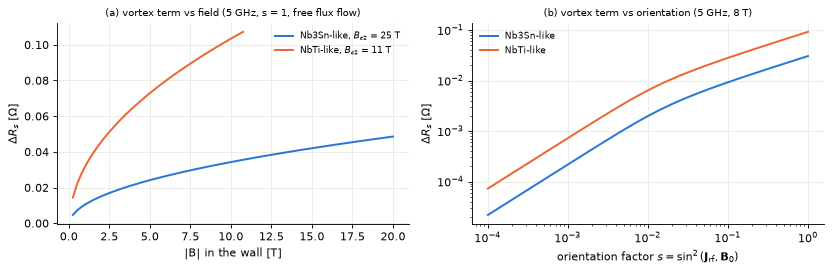

In [26]:
for name, ff in (("Nb3Sn-like", NB3SN_FF), ("NbTi-like", NBTI_FF)):
    _, dR = Rs(flux_flow_only(ff, B_T=8.0, s=1.0), 5e9, flux_flow_part=True)
    print(f"{name:11s}: Delta R_s(5 GHz, 8 T, s = 1) = {dR:.4f} ohm   (docs: {0.031 if ff is NB3SN_FF else 0.092})")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10.5, 3.5))
B = np.linspace(0.25, 20, 80)
for name, ff, col in (("Nb3Sn-like", NB3SN_FF, BLUE), ("NbTi-like", NBTI_FF, ORANGE)):
    Bok = B[B < ff["Bc2_T"]]
    ax0.plot(Bok, [Rs(flux_flow_only(ff, B_T=b, s=1.0), 5e9) for b in Bok], color=col, label=f"{name}, $B_{{c2}}$ = {ff['Bc2_T']:g} T")
s = np.geomspace(1e-4, 1, 60)
for name, ff, col in (("Nb3Sn-like", NB3SN_FF, BLUE), ("NbTi-like", NBTI_FF, ORANGE)):
    ax1.loglog(s, [Rs(flux_flow_only(ff, B_T=8.0, s=x), 5e9) for x in s], color=col, label=name)
ax0.set_xlabel("|B| in the wall [T]"); ax0.set_ylabel(r"$\Delta R_s$ [$\Omega$]")
ax0.set_title("(a) vortex term vs field (5 GHz, s = 1, free flux flow)", fontsize=9); ax0.legend(fontsize=8)
ax1.set_xlabel(r"orientation factor $s=\sin^2(\mathbf{J}_{\rm rf},\mathbf{B}_0)$"); ax1.set_ylabel(r"$\Delta R_s$ [$\Omega$]")
ax1.set_title("(b) vortex term vs orientation (5 GHz, 8 T)", fontsize=9); ax1.legend(fontsize=8)
fig.tight_layout(); plt.show()

The plot compares frequency dependence across the models.

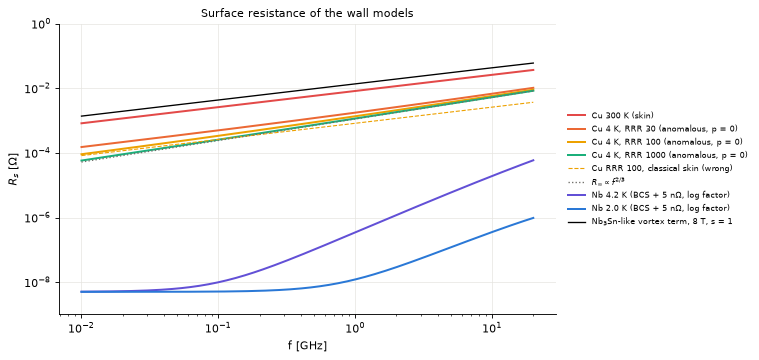

In [27]:
f = np.geomspace(1e7, 2e10, 200)
fig, ax = plt.subplots(figsize=(9.6, 4.6))
ax.loglog(f / 1e9, Rs(CU_300K, f), color=RED, label="Cu 300 K (skin)")
for rrr, col, ls in ((30, ORANGE, "-"), (100, GOLD, "-"), (1000, GREEN, "-")):
    ax.loglog(f / 1e9, Rs(cu_cold(rrr), f), color=col, ls=ls, label=f"Cu 4 K, RRR {rrr} (anomalous, p = 0)")
ax.loglog(f / 1e9, Rs({"model": "skin", "rho_ohm_m": RHO300 / 100, "T_K": 4}, f), color=GOLD, ls="--", lw=1.0, label="Cu RRR 100, classical skin (wrong)")
ax.loglog(f / 1e9, (math.sqrt(3) * RHOL_CU * (MU0 * 2 * np.pi * f) ** 2 / (16 * math.pi)) ** (1 / 3), color=GREY, ls=":",
          lw=1.2, label=r"$R_\infty\propto f^{2/3}$")
for T, col in ((4.2, VIOLET), (2.0, BLUE)):
    ax.loglog(f / 1e9, Rs(dict(NB_RES, T_K=T), f), color=col, label=f"Nb {T} K (BCS + 5 n$\\Omega$, log factor)")
ax.loglog(f / 1e9, Rs(flux_flow_only(NB3SN_FF, B_T=8.0, s=1.0), f), color="k", lw=1.2,
          label="Nb$_3$Sn-like vortex term, 8 T, s = 1")
ax.set_xlabel("f [GHz]"); ax.set_ylabel(r"$R_s$ [$\Omega$]"); ax.set_ylim(1e-9, 1)
ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5)); ax.set_title("Surface resistance of the wall models", fontsize=10)
fig.tight_layout(); plt.show()

### Pillbox with each wall

The wall's `rf` settings determine losses after the lossless eigenmode solve. Read `G_ohm`, `Q0` and per-wall resistance from `cavity_modes()`; refine the mesh to check $G$.

In [28]:
A, L = 0.1, 0.2
G_exact = Z0 * CHI01 * L / (2 * (A + L))
walls = {"Cu 300 K, rho 1.68e-8 (skin)": {"kind": "conductor", "rf": {"model": "skin", "rho_ohm_m": 1.68e-8, "T_K": 300}},
         "Cu 4 K, RRR 100 of 1.68e-8 (anomalous)": {"kind": "conductor", "rf": cu_cold(100, rho300=1.68e-8)},
         "builtin 'copper'": "copper",
         "Nb 2 K (bcs, log factor, R_res 5 nOhm)": {"kind": "conductor", "rf": NB_RES}}
rows = {}
for name, wall in walls.items():
    d = cv.pillbox_design(A, L, h=A / 5, modes=1, families=("TM",), domain_radius=1.0,
                          wall_material=None if isinstance(wall, str) else wall)
    if isinstance(wall, str):
        d.doc["regions"][1]["material"] = wall           # a builtin material by name
    r = d.solve(RUNS / f"pillbox_{len(rows)}", verbose=0)
    m = r.cavity_modes()[0]
    rows[name] = (m, r.data["warnings"])
print(f"{len(rows)} solves, {r.data['mesh']['dofs']} DOFs each")
print(f"G closed form = {G_exact:.3f} ohm\n")
print(f"{'wall':42s}{'f [GHz]':>9s}{'G [ohm]':>9s}{'G/G_ex-1':>10s}{'R_s':>12s}{'Q0 (solver)':>13s}{'G/R_s-Q0':>10s}")
for name, (m, warn) in rows.items():
    w = m["walls"]["wall"]
    print(f"{name:42s}{m['f_Hz']/1e9:9.5f}{m['G_ohm']:9.3f}{m['G_ohm']/G_exact-1:10.1e}{w['Rs_ohm']:12.4e}"
          f"{m['Q0']:13.4e}{m['G_ohm']/w['Rs_ohm']/m['Q0']-1:10.1e}")
for name, (m, warn) in rows.items():     # every solve also warns that a background field (the 1 T Bz of the builder,
    w = [x for x in warn if "background field" not in x]   # used for C only) is present; that one is filtered here
    if w:
        print(f"\nwarnings ({name}):", *w, sep="\n  ")

4 solves, 7547 DOFs each
G closed form = 301.990 ohm

wall                                        f [GHz]  G [ohm]  G/G_ex-1         R_s  Q0 (solver)  G/R_s-Q0
Cu 300 K, rho 1.68e-8 (skin)                1.14743  301.988  -7.4e-06  8.7236e-03   3.4617e+04   2.2e-16
Cu 4 K, RRR 100 of 1.68e-8 (anomalous)      1.14743  301.988  -7.4e-06  1.4741e-03   2.0487e+05   0.0e+00
builtin 'copper'                            1.14743  301.988  -7.4e-06  1.4764e-03   2.0454e+05   2.2e-16
Nb 2 K (bcs, log factor, R_res 5 nOhm)      1.14743  301.988  -7.4e-06  1.4069e-08   2.1465e+10   0.0e+00


### Losses on individual walls

At 5 GHz in an axial 8 T field, the ideal barrel current is parallel to the vortices; the end caps carry the vortex loss.

In [29]:
F5 = 5e9
A5 = CHI01 * cv.C_LIGHT / (2 * math.pi * F5); L5 = 2 * A5; t5 = A5 / 10
nb3sn_wall = {"kind": "conductor", "rf": flux_flow_only(NB3SN_FF)}            # B from the field, s per wall point
d = cv.pillbox_design(A5, L5, h=A5 / 5, modes=1, families=("TM",), wall_material=nb3sn_wall, Bz=8.0,
                      domain_radius=10 * A5)     # sphere large enough that its element-size cap pi R/96 exceeds h
d.doc["regions"] = [d.doc["regions"][0],
                    {"name": "barrel", "shape": {"rect": {"r": [A5, A5 + t5], "z": [-L5 / 2 - t5, L5 / 2 + t5]}},
                     "material": "wall_cu"},
                    {"name": "cap_top", "shape": {"rect": {"r": [0.0, A5], "z": [L5 / 2, L5 / 2 + t5]}}, "material": "wall_cu"},
                    {"name": "cap_bot", "shape": {"rect": {"r": [0.0, A5], "z": [-L5 / 2 - t5, -L5 / 2]}}, "material": "wall_cu"}]
r5 = d.solve(RUNS / "pillbox_5GHz_8T", verbose=0)
m5 = r5.cavity_modes()[0]
print(f"a = {A5*100:.3f} cm, L = {L5*100:.3f} cm: f = {m5['f_Hz']/1e9:.5f} GHz, V = {m5['V_m3']*1e6:.2f} cm^3, "
      f"C = {m5['C']:.4f}, G = {m5['G_ohm']:.2f} ohm (scale-free: same as at 1.15 GHz)")
print(f"\n{'wall':9s}{'G_w [ohm]':>11s}{'s (|H_t|^2-wtd)':>17s}{'dR_s(s) [ohm]':>15s}{'dR_s(s=1)':>11s}{'Q_w':>11s}{'loss share':>12s}")
for name, w in m5["walls"].items():
    print(f"{name:9s}{w['G_ohm']:11.2f}{w['flux_flow_orientation_factor']:17.3f}{w['Rs_flux_flow_ohm']:15.4e}"
          f"{w['Rs_flux_flow_perpendicular_ohm']:11.4f}{w['Q']:11.3e}{w['P_frac']:12.3f}")
Q0_field = m5["Q0"]
Q0_perp = m5["G_ohm"] / m5["walls"]["cap_top"]["Rs_flux_flow_perpendicular_ohm"]     # s = 1 on every wall
print(f"\nQ0 with the orientation factor = {Q0_field:.4g};  Q0 with s = 1 everywhere (G/dR_s) = {Q0_perp:.4g}")
print("solver warnings (all, in full):", *r5.data["warnings"], sep="\n  ")

a = 2.295 cm, L = 4.590 cm: f = 5.00001 GHz, V = 75.94 cm^3, C = 0.6917, G = 301.99 ohm (scale-free: same as at 1.15 GHz)

wall       G_w [ohm]  s (|H_t|^2-wtd)  dR_s(s) [ohm]  dR_s(s=1)        Q_w  loss share
barrel        452.98            0.000     0.0000e+00     0.0306  4.530e+32       0.000
cap_bot      1811.94            1.000     3.0628e-02     0.0306  5.916e+04       0.500
cap_top      1811.94            1.000     3.0628e-02     0.0306  5.916e+04       0.500

Q0 with the orientation factor = 2.958e+04;  Q0 with s = 1 everywhere (G/dR_s) = 9860
solver warnings (all, in full):
  cavity: material 'wall_cu': R_s includes a flux_flow (vortex) term: an order-of-magnitude model with large uncertainty (pinning, creep, B_c2(T), lambda and rho_n of real walls; docs/physics/surface_resistance.md Sec. 4); orientation factor sin^2(J, B0) per wall point where the engine computes it (cavity wall losses: axisymmetric, cross-section and 3D), else 1 (current perpendicular to the vortices: upper 

Imperfect alignment restores barrel losses. The next plot varies its orientation factor while keeping the end caps perpendicular.

barrel s = 0.001: Q0 = 2.916e+04
barrel s = 0.01: Q0 = 2.619e+04


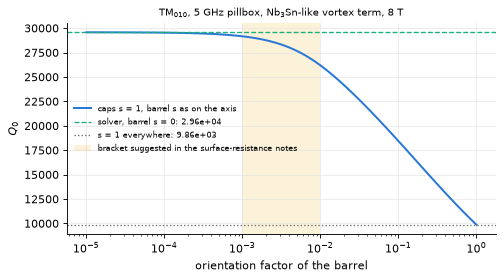

In [30]:
Gw = {k: w["G_ohm"] for k, w in m5["walls"].items()}
dR_cap = m5["walls"]["cap_top"]["Rs_flux_flow_ohm"]
sb = np.geomspace(1e-5, 1, 61)
Q0_s = np.array([1 / (Rs(flux_flow_only(NB3SN_FF, B_T=8.0, s=x), m5["f_Hz"]) / Gw["barrel"]
                      + dR_cap / Gw["cap_top"] + dR_cap / Gw["cap_bot"]) for x in sb])
for x in (1e-3, 1e-2):
    print(f"barrel s = {x:g}: Q0 = {np.interp(math.log(x), np.log(sb), Q0_s):.4g}")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.semilogx(sb, Q0_s, color=BLUE, label="caps s = 1, barrel s as on the axis")
ax.axhline(Q0_field, color=GREEN, ls="--", lw=1.2, label=f"solver, barrel s = 0: {Q0_field:.3g}")
ax.axhline(Q0_perp, color=GREY, ls=":", lw=1.2, label=f"s = 1 everywhere: {Q0_perp:.3g}")
ax.axvspan(1e-3, 1e-2, color=GOLD, alpha=0.15, lw=0, label="bracket suggested in the surface-resistance notes")
ax.set_xlabel("orientation factor of the barrel"); ax.set_ylabel("$Q_0$")
ax.set_title("TM$_{010}$, 5 GHz pillbox, Nb$_3$Sn-like vortex term, 8 T", fontsize=9); ax.legend(fontsize=7.5)
fig.tight_layout(); plt.show()

### Frequency and temperature

Rescaling the pillbox preserves its geometry factor. These plots therefore isolate changes in the wall resistance.

Q0 of TM010 at 1.147 GHz (G = 301.99 ohm):
   copper     4 K: R_s = 1.479 mOhm, Q0 = 2.04e+05
   copper    77 K: R_s = 3.066 mOhm, Q0 = 9.85e+04
   copper   300 K: R_s = 8.840 mOhm, Q0 = 3.42e+04
   niobium  4.2 K (+5 nOhm): R_s = 442.67 nOhm, Q0 = 6.82e+08
   niobium  2.0 K (+5 nOhm): R_s = 14.07 nOhm, Q0 = 2.15e+10
   niobium  1.5 K (+5 nOhm): R_s = 5.64 nOhm, Q0 = 5.36e+10


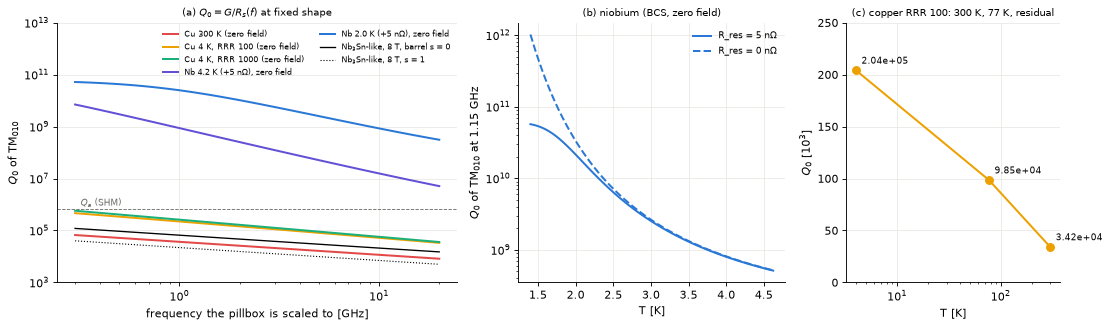

In [31]:
G = rows["Cu 4 K, RRR 100 of 1.68e-8 (anomalous)"][0]["G_ohm"]            # the solved G (= 302 ohm)
f1 = rows["Cu 4 K, RRR 100 of 1.68e-8 (anomalous)"][0]["f_Hz"]
f = np.geomspace(3e8, 2e10, 120)
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
ax0.loglog(f / 1e9, G / Rs(CU_300K, f), color=RED, label="Cu 300 K (zero field)")
ax0.loglog(f / 1e9, G / Rs(cu_cold(100), f), color=GOLD, label="Cu 4 K, RRR 100 (zero field)")
ax0.loglog(f / 1e9, G / Rs(cu_cold(1000), f), color=GREEN, label="Cu 4 K, RRR 1000 (zero field)")
for T, col in ((4.2, VIOLET), (2.0, BLUE)):
    ax0.loglog(f / 1e9, G / Rs(dict(NB_RES, T_K=T), f), color=col, label=f"Nb {T} K (+5 n$\\Omega$), zero field")
dR = Rs(flux_flow_only(NB3SN_FF, B_T=8.0, s=1.0), f)
ax0.loglog(f / 1e9, 1 / (dR / Gw["cap_top"] + dR / Gw["cap_bot"]), color="k", lw=1.2, label="Nb$_3$Sn-like, 8 T, barrel s = 0")
ax0.loglog(f / 1e9, G / dR, color="k", lw=1.0, ls=":", label="Nb$_3$Sn-like, 8 T, s = 1")
ax0.axhline(hs.Q_a_shm(), color=GREY, lw=0.8, ls="--"); ax0.text(0.32, hs.Q_a_shm() * 1.3, "$Q_a$ (SHM)", fontsize=8, color=GREY)
ax0.set_xlabel("frequency the pillbox is scaled to [GHz]"); ax0.set_ylabel("$Q_0$ of TM$_{010}$")
ax0.set_title("(a) $Q_0=G/R_s(f)$ at fixed shape", fontsize=9); ax0.legend(fontsize=7, ncol=2, loc="upper right")
ax0.set_ylim(1e3, 1e13)

T = np.linspace(1.4, 9.25 / 2 - 1e-3, 80)
for Rres, ls in ((5e-9, "-"), (0.0, "--")):
    ax1.semilogy(T, [G / Rs(dict(NB, T_K=t, R_res_ohm=Rres, log_factor=True), f1) for t in T], color=BLUE, ls=ls,
                 label=f"R_res = {Rres*1e9:g} n$\\Omega$")
ax1.set_xlabel("T [K]"); ax1.set_ylabel(f"$Q_0$ of TM$_{{010}}$ at {f1/1e9:.2f} GHz")
ax1.set_title("(b) niobium (BCS, zero field)", fontsize=9); ax1.legend(fontsize=8)

cu_T = {4.0: cu_cold(100), 77.0: {"model": "anomalous", "rho_ohm_m": 2e-9, "rho_l_ohm_m2": RHOL_CU, "T_K": 77},
        300.0: {"model": "anomalous", "rho_ohm_m": RHO300, "rho_l_ohm_m2": RHOL_CU, "T_K": 300}}
print(f"Q0 of TM010 at {f1/1e9:.3f} GHz (G = {G:.2f} ohm):")
for t, rf in cu_T.items():
    print(f"   copper {t:5.0f} K: R_s = {Rs(rf, f1)*1e3:.3f} mOhm, Q0 = {G / Rs(rf, f1):.3g}")
for t in (4.2, 2.0, 1.5):
    print(f"   niobium {t:4.1f} K (+5 nOhm): R_s = {Rs(dict(NB_RES, T_K=t), f1)*1e9:.2f} nOhm, Q0 = {G/Rs(dict(NB_RES, T_K=t), f1):.3g}")
ax2.semilogx(list(cu_T), [G / Rs(rf, f1) / 1e3 for rf in cu_T.values()], "o-", color=GOLD, ms=7)
for t, rf in cu_T.items():
    ax2.annotate(f"{G / Rs(rf, f1):.3g}", (t, G / Rs(rf, f1) / 1e3), textcoords="offset points", xytext=(5, 6), fontsize=8)
ax2.set_xlabel("T [K]"); ax2.set_ylabel("$Q_0$ [$10^3$]"); ax2.set_ylim(0, 250)
ax2.set_title("(c) copper RRR 100: 300 K, 77 K, residual", fontsize=9)
fig.tight_layout(); plt.show()

### Scan rate

For flat receiver noise, optimal weighting gives a scan rate proportional to $Q_0$ at fixed frequency, coupling and geometry. The alternative binned estimator saturates at high $Q_0$.

In [32]:
f5, V5, C5 = m5["f_Hz"], m5["V_m3"], m5["C"]
G5 = m5["G_ohm"]
rx = hs.Receiver(T_sys_K=0.5)
gD = float(hs.g_axion(hs.freq_to_mass_eV(f5), "DFSZ"))
walls5 = {"Cu 300 K (zero field)": G5 / Rs(CU_300K, f5),
          "Cu 4 K, RRR 100 (zero field)": G5 / Rs(cu_cold(100), f5),
          "Nb3Sn-like 8 T, s = 1": Q0_perp,
          "Nb3Sn-like 8 T, barrel s = 0": Q0_field,
          "Nb 2 K + 5 nOhm (zero field!)": G5 / Rs(NB_RES, f5)}
print(f"5 GHz pillbox: V = {V5*1e6:.2f} cm^3, C = {C5:.3f}, B = 8 T, T_sys = 0.5 K, g = g_DFSZ = {gD:.3e} GeV^-1, SNR 5\n")
print(f"{'wall':31s}{'Q0':>10s}{'beta_opt':>9s}{'rate [Hz/s]':>13s}{'/ Cu 4 K':>10s}{'g_lim ratio':>12s}"
      f"{'K20 beta':>10s}{'K20 rate':>11s}{'/ Cu 4 K':>10s}")
out = {}
for name, Q0 in walls5.items():
    cav = hs.Cavity(B_T=8.0, V_m3=V5, C=C5, Q0=Q0, beta=2.0)
    b = hs.beta_opt(f5, cav, rx, g_GeV=gD)
    rate = hs.scan_rate(f5, hs.Cavity(8.0, V5, C5, Q0, b), rx, g_GeV=gD, snr=5.0)
    bk = hs.beta_opt_kim2020(Q0, 1e6)
    rk = hs.scan_rate_kim2020(f5, hs.Cavity(8.0, V5, C5, Q0, bk), g_GeV=gD, T_sys_K=0.5, snr=5.0, Q_a_kim=1e6)
    out[name] = (Q0, b, rate, bk, rk)
ref = out["Cu 4 K, RRR 100 (zero field)"]
for name, (Q0, b, rate, bk, rk) in out.items():
    print(f"{name:31s}{Q0:10.3g}{b:9.2f}{rate:13.3g}{rate/ref[2]:10.3g}{(rate/ref[2])**-0.25:12.3f}"
          f"{bk:10.2f}{rk:11.3g}{rk/ref[4]:10.3g}")

5 GHz pillbox: V = 75.94 cm^3, C = 0.692, B = 8 T, T_sys = 0.5 K, g = g_DFSZ = 2.872e-15 GeV^-1, SNR 5

wall                                   Q0 beta_opt  rate [Hz/s]  / Cu 4 K g_lim ratio  K20 beta   K20 rate  / Cu 4 K
Cu 300 K (zero field)            1.64e+04     2.00      3.4e-05     0.202       1.492      2.01   6.35e-05     0.206
Cu 4 K, RRR 100 (zero field)      8.1e+04     2.00     0.000168         1       1.000      2.05   0.000308         1
Nb3Sn-like 8 T, s = 1            9.86e+03     2.00     2.05e-05     0.122       1.693      2.01   3.84e-05     0.125
Nb3Sn-like 8 T, barrel s = 0     2.96e+04     2.00     6.15e-05     0.365       1.287      2.02   0.000114     0.371
Nb 2 K + 5 nOhm (zero field!)    2.52e+09     2.00         5.25  3.12e+04       0.075     71.57     0.0249      80.9


The table gives rates in hertz per second and sensitivity ratios relative to cold copper. Zero-field copper and niobium rows do not predict performance in an 8 T magnet; use measured resistance at the operating field for predictions.

## COMSOL geometry export

`comsol.export_comsol` writes a design as a COMSOL Java model (or as an `.mphtxt` mesh) with one named selection per
region. The Java export contains geometry and named selections; it does not create a cavity eigenfrequency study.

We export the 5 GHz pillbox above, with its three wall regions, as a Java model.

In [33]:
from axionfem import comsol

export = comsol.export_comsol(d, RUNS / "Pillbox5GHz.java", format="java")
print(Path(export["file"]).name, export["class"], f"dimension {export['dimension']}")
print("selections:", export["selections"])
print("approximations:", export["approximations"])

Pillbox5GHz.java Pillbox5GHz dimension 2
selections: ['air', 'barrel', 'cap_bot', 'cap_top', 'cavity']
approximations: []


See the [surface resistance](../docs/physics/surface_resistance.md) and [cavity sensitivity](../docs/physics/haloscope_sensitivity.md) notes and the [cavity API](../docs/api.md). The geometry export to COMSOL is described in the [COMSOL guide](../docs/guides/comsol.md).